[1/64] L2=0, Batch=8, LR=0.01
[2/64] L2=0, Batch=8, LR=0.001
[3/64] L2=0, Batch=8, LR=0.0005
[4/64] L2=0, Batch=8, LR=0.0001
[5/64] L2=0, Batch=16, LR=0.01
[6/64] L2=0, Batch=16, LR=0.001
[7/64] L2=0, Batch=16, LR=0.0005
[8/64] L2=0, Batch=16, LR=0.0001
[9/64] L2=0, Batch=32, LR=0.01
[10/64] L2=0, Batch=32, LR=0.001
[11/64] L2=0, Batch=32, LR=0.0005
[12/64] L2=0, Batch=32, LR=0.0001
[13/64] L2=0, Batch=64, LR=0.01
[14/64] L2=0, Batch=64, LR=0.001
[15/64] L2=0, Batch=64, LR=0.0005
[16/64] L2=0, Batch=64, LR=0.0001
[17/64] L2=1e-06, Batch=8, LR=0.01
[18/64] L2=1e-06, Batch=8, LR=0.001
[19/64] L2=1e-06, Batch=8, LR=0.0005
[20/64] L2=1e-06, Batch=8, LR=0.0001
[21/64] L2=1e-06, Batch=16, LR=0.01
[22/64] L2=1e-06, Batch=16, LR=0.001
[23/64] L2=1e-06, Batch=16, LR=0.0005
[24/64] L2=1e-06, Batch=16, LR=0.0001
[25/64] L2=1e-06, Batch=32, LR=0.01
[26/64] L2=1e-06, Batch=32, LR=0.001
[27/64] L2=1e-06, Batch=32, LR=0.0005
[28/64] L2=1e-06, Batch=32, LR=0.0001
[29/64] L2=1e-06, Batch=64, LR=0.01
[3

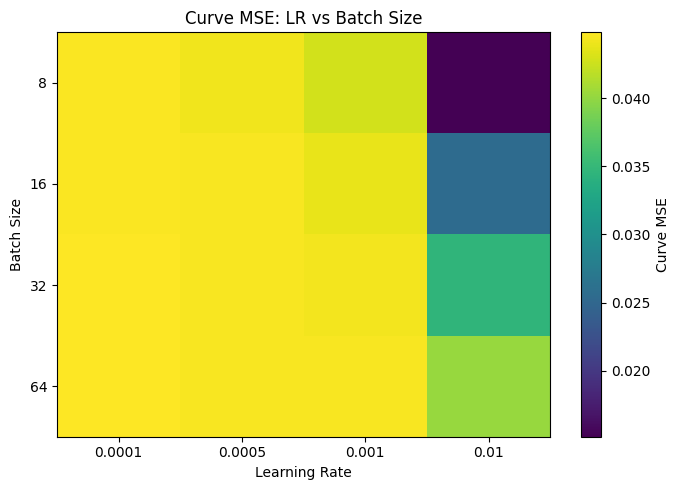

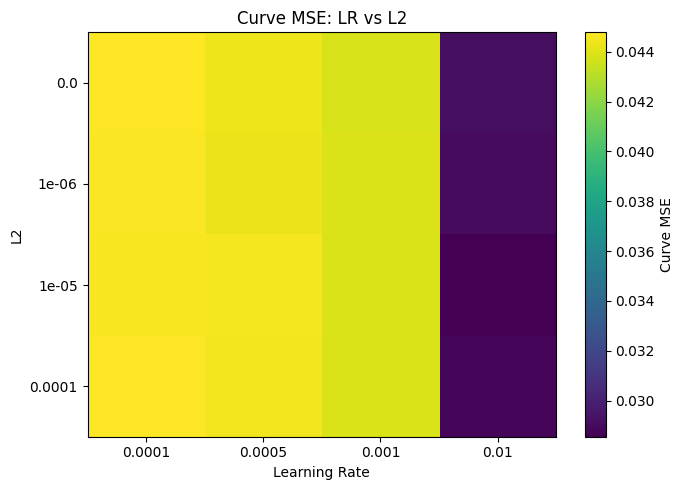

In [ ]:
# =========================================================
# FAST REPRODUCIBLE COMBINED HYPERPARAMETER STUDY
# PHYSICS-GUIDED MBVD FORMULATION
# =========================================================

import os
import gc
import random
import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product

# =========================================================
# FULL REPRODUCIBILITY
# =========================================================
SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

tf.get_logger().setLevel("ERROR")

# =========================================================
# CONSTANTS
# =========================================================
PI = np.pi

N_FREQ = 200
N_SYNTH = 120

# =========================================================
# FAST SETTINGS
# =========================================================
SELECTED_INDICES = [0,4,8,12,16,20]

MAX_EPOCHS = 120

# =========================================================
# HYPERPARAMETERS
# =========================================================
learning_rates = [1e-2,1e-3,5e-4,1e-4]

batch_sizes = [8,16,32,64]

l2_values = [0,1e-6,1e-5,1e-4]

# =========================================================
# REAL RESONATORS
# =========================================================
# INPUT DESCRIPTORS:
# (Cs, fr, Qs, Qp, R0, k2)
# =========================================================
real_resonators = [

{"Cs":7.95e-13,"fr":2468e6,"Qs":887,"Qp":3770,"R0":0.257,"k2":0.080},
{"Cs":5.989e-13,"fr":2466e6,"Qs":1034,"Qp":1379,"R0":0.257,"k2":0.080},
{"Cs":3.981e-13,"fr":2468e6,"Qs":1994,"Qp":1052,"R0":0.257,"k2":0.085},
{"Cs":1.857e-12,"fr":2461e6,"Qs":935,"Qp":2513,"R0":0.257,"k2":0.081},
{"Cs":1.39e-12,"fr":2488e6,"Qs":804,"Qp":1732,"R0":0.257,"k2":0.084},
{"Cs":1.65e-12,"fr":2324e6,"Qs":1038,"Qp":1112,"R0":0.257,"k2":0.091},
{"Cs":1.70e-12,"fr":2324e6,"Qs":911,"Qp":1683,"R0":0.257,"k2":0.0855},
{"Cs":2.60e-12,"fr":1298e6,"Qs":1470,"Qp":2580,"R0":0.257,"k2":0.093},
{"Cs":2.03e-12,"fr":1487e6,"Qs":1249,"Qp":1966,"R0":0.257,"k2":0.097},
{"Cs":2.36e-12,"fr":1477e6,"Qs":904,"Qp":1153,"R0":0.257,"k2":0.096},
{"Cs":1.096e-12,"fr":1722e6,"Qs":2688,"Qp":3530,"R0":0.257,"k2":0.092},
{"Cs":3.01e-12,"fr":1443e6,"Qs":1353,"Qp":1585,"R0":0.257,"k2":0.091},
{"Cs":3.244e-12,"fr":1269e6,"Qs":1643,"Qp":1645,"R0":0.257,"k2":0.0891},
{"Cs":1.242e-12,"fr":2847e6,"Qs":906,"Qp":2170,"R0":0.257,"k2":0.0747},
{"Cs":1.592e-12,"fr":2467e6,"Qs":832,"Qp":2911,"R0":0.257,"k2":0.0846},
{"Cs":1.90e-12,"fr":2314e6,"Qs":1181,"Qp":2603,"R0":0.257,"k2":0.086},
{"Cs":2.132e-12,"fr":2074e6,"Qs":892,"Qp":3792,"R0":0.257,"k2":0.089},
{"Cs":2.47e-12,"fr":1719e6,"Qs":974,"Qp":4742,"R0":0.257,"k2":0.090},
{"Cs":1.07e-12,"fr":1723e6,"Qs":2291,"Qp":1939,"R0":0.257,"k2":0.093},
{"Cs":2.02e-12,"fr":1485e6,"Qs":1089,"Qp":6853,"R0":0.257,"k2":0.094},
{"Cs":1.57e-12,"fr":2467e6,"Qs":1095,"Qp":1312,"R0":0.257,"k2":0.0868},
{"Cs":1.58e-12,"fr":2092e6,"Qs":857,"Qp":1712,"R0":0.257,"k2":0.092}

]

# =========================================================
# SYNTHETIC DATA
# =========================================================
def generate_synthetic_resonators(n):

    resonators=[]

    while len(resonators)<n:

        resonators.append({

            "Cs": np.random.uniform(0.5e-12,3.5e-12),

            "fr": np.random.uniform(1.2e9,2.8e9),

            "Qs": np.random.uniform(600,3000),

            "Qp": np.random.uniform(1000,7000),

            "R0": 0.257,

            "k2": np.random.uniform(0.075,0.10)

        })

    return resonators

# =========================================================
# PHYSICS-GUIDED MBVD PARAMETERS
# =========================================================
def compute_mbvd_parameters(r):

    Cs=r["Cs"]

    fr=r["fr"]

    Qs=r["Qs"]

    Qp=r["Qp"]

    R0=r["R0"]

    k2=r["k2"]

    # =====================================================
    # ANTI-RESONANCE FREQUENCY
    # =====================================================
    fa=(

        2*fr

        /

        (

            1 +

            np.sqrt(

                1 - (16*k2)/(PI**2)

            )

        )

    )

    wr=2*PI*fr

    wa=2*PI*fa

    # =====================================================
    # MOTIONAL CAPACITANCE
    # =====================================================
    Cm=Cs*((fa/fr)**2 -1)

    # =====================================================
    # MOTIONAL INDUCTANCE
    # =====================================================
    Lm=1/((wr**2)*Cm)

    # =====================================================
    # MOTIONAL RESISTANCE
    # =====================================================
    Rm=wr*(Lm/Qs) - R0

    # =====================================================
    # STATIC BRANCH LOSS
    # =====================================================
    Rs=wa*(Lm/Qp) - Rm

    # =====================================================
    # SAFETY
    # =====================================================
    Rm=np.maximum(Rm,1e-6)

    Rs=np.maximum(Rs,1e-6)

    Cm=np.maximum(Cm,1e-18)

    Lm=np.maximum(Lm,1e-18)

    return Rm,Lm,Cm,Cs,R0,Rs

# =========================================================
# PHYSICS-GUIDED MBVD RESPONSE
# =========================================================
def compute_Y11(r):

    fr=r["fr"]

    Rm,Lm,Cm,Cs,R0,Rs=compute_mbvd_parameters(r)

    fa=(

        2*fr

        /

        (

            1 +

            np.sqrt(

                1 - (16*r["k2"])/(PI**2)

            )

        )

    )

    f=np.linspace(

        fr*0.93,
        fa*1.07,
        N_FREQ,
        dtype=np.float32

    )

    w=2*PI*f

    # =====================================================
    # STATIC BRANCH
    # =====================================================
    Zs=R0 + 1/(1j*w*Cs)

    # =====================================================
    # MOTIONAL BRANCH
    # =====================================================
    Zm=Rm + 1/(1j*w*Cm) + 1j*w*Lm

    # =====================================================
    # PARALLEL NETWORK
    # =====================================================
    Zp=1/(1/Zs + 1/Zm)

    # =====================================================
    # TOTAL IMPEDANCE
    # =====================================================
    Ztotal=Rs + Zp

    Y11=np.abs(1/Ztotal).astype(np.float32)

    return Y11,f

# =========================================================
# EXTRACT FREQUENCIES
# =========================================================
def extract_frequencies(Y,f):

    return (

        f[np.argmax(Y)],
        f[np.argmin(Y)]

    )

# =========================================================
# PRECOMPUTE CURVES
# =========================================================
synthetic_resonators=generate_synthetic_resonators(N_SYNTH)

all_res=real_resonators + synthetic_resonators

Y_cache={

    id(r):compute_Y11(r)

    for r in all_res

}

freq_cache={}

for r in all_res:

    Y,f=Y_cache[id(r)]

    freq_cache[id(r)]=extract_frequencies(Y,f)

# =========================================================
# PRECOMPUTE LOOCV DATA
# =========================================================
loo_data=[]

for idx in SELECTED_INDICES:

    test_res=real_resonators[idx]

    train_res=(

        real_resonators[:idx]
        + real_resonators[idx+1:]
        + synthetic_resonators

    )

    X=np.array([

        compute_mbvd_parameters(r)

        for r in train_res

    ],dtype=np.float32)

    Y=np.array([

        Y_cache[id(r)][0]

        for r in train_res

    ],dtype=np.float32)

    # =====================================================
    # SAFE NORMALIZATION
    # =====================================================
    Xm=X.mean(0)

    Xs=X.std(0)

    Ym=Y.mean(0)

    Ys=Y.std(0)

    Xs=np.where(Xs<1e-12,1.0,Xs)

    Ys=np.where(Ys<1e-12,1.0,Ys)

    Xn=(X-Xm)/Xs

    Yn=(Y-Ym)/Ys

    Xt=np.array([[

        *compute_mbvd_parameters(test_res)

    ]],dtype=np.float32)

    Xt=(Xt-Xm)/Xs

    loo_data.append((

        Xn,
        Yn,
        Xt,
        Ym,
        Ys,
        test_res

    ))

# =========================================================
# MODEL
# =========================================================
def build_model(lr,l2):

    reg=tf.keras.regularizers.l2(l2)

    model=tf.keras.Sequential([

        tf.keras.layers.Input((6,)),

        tf.keras.layers.Dense(
            96,
            activation="swish",
            kernel_regularizer=reg
        ),

        tf.keras.layers.Dense(
            96,
            activation="swish",
            kernel_regularizer=reg
        ),

        tf.keras.layers.Dense(
            128,
            activation="swish",
            kernel_regularizer=reg
        ),

        tf.keras.layers.Dense(
            N_FREQ,
            activation="softplus"
        )

    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=lr
        ),

        loss="mse"

    )

    return model

# =========================================================
# EARLY STOPPING
# =========================================================
early_stop=tf.keras.callbacks.EarlyStopping(

    monitor="loss",

    patience=15,

    restore_best_weights=True

)

# =========================================================
# RUN CONFIG
# =========================================================
def run_config(l2,batch,lr):

    mse_list=[]

    res_error=[]

    anti_error=[]

    for Xn,Yn,Xt,Ym,Ys,test_res in loo_data:

        model=build_model(lr,l2)

        model.fit(

            Xn,
            Yn,

            epochs=MAX_EPOCHS,

            batch_size=batch,

            shuffle=True,

            verbose=0,

            callbacks=[early_stop]

        )

        # =================================================
        # PREDICTION
        # =================================================
        Yp=model.predict(

            Xt,
            verbose=0

        )[0]

        Yp=Yp*Ys + Ym

        Yt,f=Y_cache[id(test_res)]

        # =================================================
        # METRICS
        # =================================================
        mse_list.append(

            np.mean((Yt-Yp)**2)

        )

        fr_t,fa_t=freq_cache[id(test_res)]

        fr_p,fa_p=extract_frequencies(Yp,f)

        res_error.append(

            abs(fr_t-fr_p)/1e6

        )

        anti_error.append(

            abs(fa_t-fa_p)/1e6

        )

        del model

        gc.collect()

    return (

        np.mean(mse_list),

        np.mean(res_error),

        np.mean(anti_error)

    )

# =========================================================
# RUN ALL CONFIGS
# =========================================================
results=[]

total=(

    len(l2_values)
    * len(batch_sizes)
    * len(learning_rates)

)

counter=1

for l2,batch,lr in product(

    l2_values,
    batch_sizes,
    learning_rates

):

    print(

        f"[{counter}/{total}] "
        f"L2={l2}, "
        f"Batch={batch}, "
        f"LR={lr}"

    )

    mse,res,anti=run_config(

        l2,
        batch,
        lr

    )

    results.append({

        "L2":l2,
        "Batch":batch,
        "LearningRate":lr,
        "CurveMSE":mse,
        "ResErrorMHz":res,
        "AntiResErrorMHz":anti

    })

    tf.keras.backend.clear_session()

    gc.collect()

    counter+=1

# =========================================================
# RESULTS TABLE
# =========================================================
df=pd.DataFrame(results)

df=df.sort_values(

    by="CurveMSE"

)

print("\n================ FINAL RESULTS ================\n")

print(df.to_string(index=False))

print("\n================================================")

# =========================================================
# SAVE CSV
# =========================================================
df.to_csv(

    "combined_hyperparameter_results.csv",

    index=False

)

print("\nResults saved to:")
print("combined_hyperparameter_results.csv")

# =========================================================
# HEATMAPS
# =========================================================
pivot_lr_batch=df.pivot_table(

    values="CurveMSE",
    index="Batch",
    columns="LearningRate"

)

pivot_lr_l2=df.pivot_table(

    values="CurveMSE",
    index="L2",
    columns="LearningRate"

)

# =========================================================
# LR vs BATCH
# =========================================================
plt.figure(figsize=(7,5))

plt.imshow(

    pivot_lr_batch.values,
    aspect="auto"

)

plt.xticks(

    range(len(pivot_lr_batch.columns)),
    pivot_lr_batch.columns

)

plt.yticks(

    range(len(pivot_lr_batch.index)),
    pivot_lr_batch.index

)

plt.xlabel("Learning Rate")

plt.ylabel("Batch Size")

plt.title("Curve MSE: LR vs Batch Size")

plt.colorbar(label="Curve MSE")

plt.tight_layout()

plt.show()

# =========================================================
# LR vs L2
# =========================================================
plt.figure(figsize=(7,5))

plt.imshow(

    pivot_lr_l2.values,
    aspect="auto"

)

plt.xticks(

    range(len(pivot_lr_l2.columns)),
    pivot_lr_l2.columns

)

plt.yticks(

    range(len(pivot_lr_l2.index)),
    pivot_lr_l2.index

)

plt.xlabel("Learning Rate")

plt.ylabel("L2")

plt.title("Curve MSE: LR vs L2")

plt.colorbar(label="Curve MSE")

plt.tight_layout()

plt.show()